# Aula 02 — Prática · Primeiro contato com a base

**Visualização e Interpretação de Dados** · primeira aula prática do módulo

Nesta aula: carregamos a base que acompanha o módulo inteiro, entendemos o que cada coluna
significa, conferimos se o dado merece confiança e damos a primeira olhada na variável central.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

plt.rcParams.update(
    {
        "figure.figsize": (10, 5.6),
        "figure.dpi": 110,
        "font.size": 13,
        "axes.grid": True,
        "grid.alpha": 0.3,
    }
)

# RAIZ = a pasta uma acima da pasta deste notebook: contém base_curada.csv, environment.yml
# e as pastas aula-XX. Encontrada subindo a partir do diretório de trabalho.
RAIZ = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "base_curada.csv").is_file()
)
BASE = RAIZ / "base_curada.csv"

## A base

Dados públicos de produtividade agrícola por região, cultura e safra, de 1997 a 2019.
O recorte preparado para o módulo tem cinco culturas e as colunas que interessam à nossa leitura.

In [2]:
dados = pd.read_csv(BASE)

perfil_base = pd.DataFrame(
    {
        "linhas": [len(dados)],
        "colunas": [dados.shape[1]],
        "período": [f"{dados['ano'].min()}–{dados['ano'].max()}"],
    }
)
perfil_base

,linhas,colunas,período
0,3668,11,1997–2019


## As primeiras linhas

In [3]:
amostra = dados.head()

display(
    amostra.style.set_properties(
        subset=["chuva_mm", "fertilizante_kg_ha", "defensivo_kg_ha"]
    )
)

,ano,regiao,cultura,estacao,area_ha,producao_t,produtividade_t_ha,produtividade_informada,chuva_mm,fertilizante_kg_ha,defensivo_kg_ha
0,1997,Assam,Milho,Monção,19216.000000,14721,0.766080,0.615652,2051.400000,95.170000,0.310000
1,1997,Assam,Arroz,Outono,607358.000000,398311,0.655809,0.780870,2051.400000,95.170000,0.310000
2,1997,Assam,Arroz,Verão,174974.000000,209623,1.198024,1.060435,2051.400000,95.170000,0.310000
3,1997,Assam,Arroz,Inverno,1743321.000000,1647296,0.944918,0.941304,2051.400000,95.170000,0.310000
4,1997,Karnataka,Milho,Monção,502797.000000,1391132,2.766787,2.687778,1266.700000,95.170000,0.310000


## O que cada coluna é

<class 'pandas.DataFrame'>
RangeIndex: 3668 entries, 0 to 3667
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ano                      3668 non-null   int64  
 1   regiao                   3668 non-null   str    
 2   cultura                  3668 non-null   str    
 3   estacao                  3668 non-null   str    
 4   area_ha                  3668 non-null   float64
 5   producao_t               3668 non-null   int64  
 6   produtividade_t_ha       3668 non-null   float64
 7   produtividade_informada  3668 non-null   float64
 8   chuva_mm                 3668 non-null   float64
 9   fertilizante_kg_ha       3668 non-null   float64
 10  defensivo_kg_ha          3668 non-null   float64
dtypes: float64(6), int64(2), str(3)
memory usage: 315.3 KB


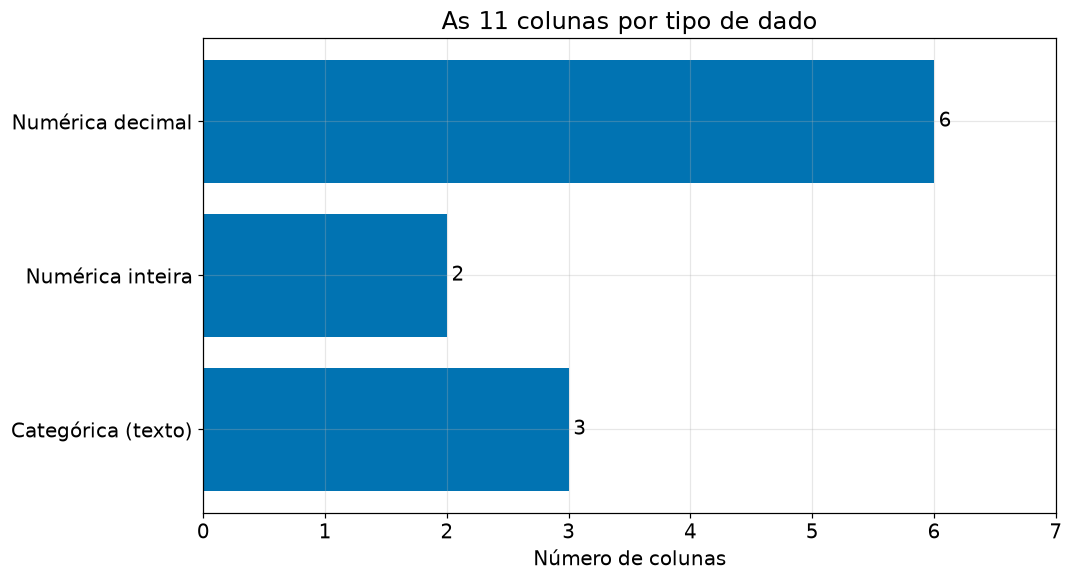

In [5]:
dados.info()

TIPOS = {
    "float64": "Numérica decimal",
    "int64": "Numérica inteira",
    "str": "Categórica (texto)",
    "object": "Categórica (texto)",
}
ORDEM = ["Numérica decimal", "Numérica inteira", "Categórica (texto)"]
classes = (
    dados.dtypes.astype(str)
    .map(TIPOS)
    .value_counts()
    .reindex(ORDEM)
    .fillna(0)
    .astype(int)
)

fig, ax = plt.subplots()
barras = ax.barh(classes.index, classes.values, color="#0173B2")
ax.bar_label(barras, padding=3)
ax.invert_yaxis()
ax.set_xlim(0, classes.max() + 1)
ax.set_xlabel("Número de colunas")
ax.set_title("As 11 colunas por tipo de dado")
plt.show()

## Faltou alguma coisa?

O `info` acima já sugere a resposta, mas a conferência explícita é um hábito que vale manter.

In [6]:
dados.isna().sum()

ano                        0
regiao                     0
cultura                    0
estacao                    0
area_ha                    0
producao_t                 0
produtividade_t_ha         0
produtividade_informada    0
chuva_mm                   0
fertilizante_kg_ha         0
defensivo_kg_ha            0
dtype: int64

## Quantas categorias existem

,Valores distintos
Região,30
Cultura,5
Estação,6


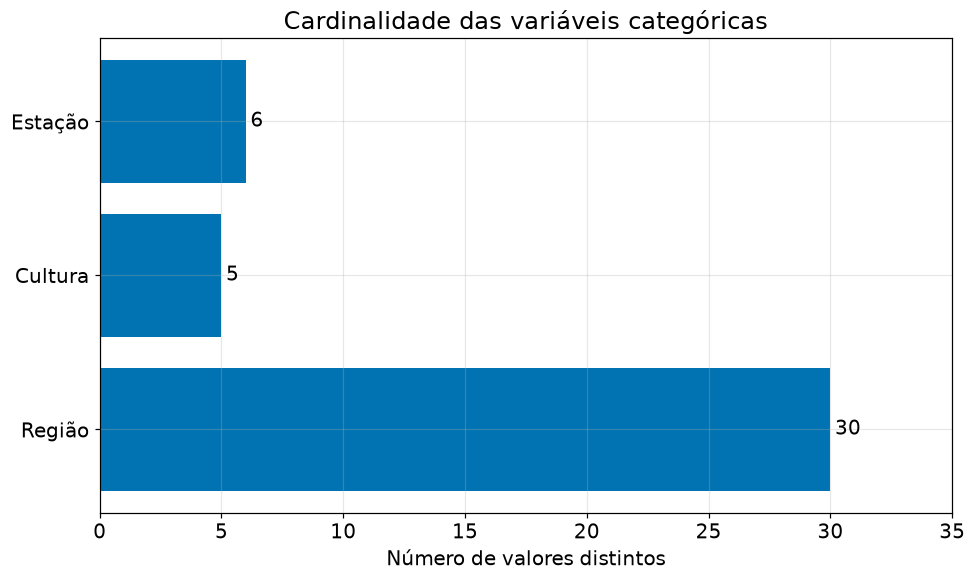

In [7]:
categorias = dados[["regiao", "cultura", "estacao"]].nunique()
categorias.index = ["Região", "Cultura", "Estação"]
display(categorias.to_frame("Valores distintos"))

fig, ax = plt.subplots()
barras = ax.barh(categorias.index, categorias.values, color="#0173B2")
ax.bar_label(barras, padding=3)
ax.set_xlim(0, categorias.max() + 5)
ax.set_xlabel("Número de valores distintos")
ax.set_title("Cardinalidade das variáveis categóricas")
plt.show()

## O resumo numérico

,area_ha,producao_t,produtividade_t_ha,chuva_mm,fertilizante_kg_ha,defensivo_kg_ha
count,3668.00,3668.00,3668.00,3668.00,3668.00,3668.00
mean,341144.48,729118.98,1.60,1432.20,137.51,0.27
std,816026.83,1921045.63,1.24,753.69,25.93,0.07
min,1.00,1.00,0.05,301.30,94.67,0.09
25%,6748.75,5323.25,0.57,956.20,108.34,0.22
50%,46190.50,48479.00,1.39,1292.70,150.80,0.27
75%,250099.25,398833.25,2.37,1686.50,157.91,0.33
max,6079822.00,16947998.00,8.14,6552.70,171.76,0.38


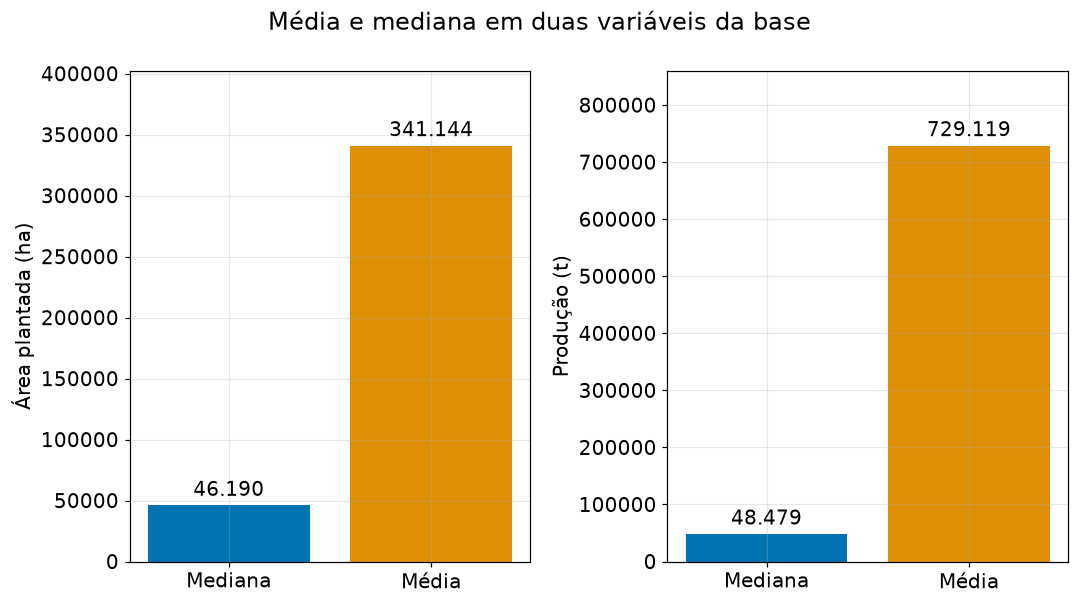

In [8]:
NUMERICAS = [
    "area_ha",
    "producao_t",
    "produtividade_t_ha",
    "chuva_mm",
    "fertilizante_kg_ha",
    "defensivo_kg_ha",
]

resumo = dados[NUMERICAS].describe().round(2)
display(resumo)

pares_resumo = [
    ("area_ha", "Área plantada (ha)"),
    ("producao_t", "Produção (t)"),
]
fig, eixos = plt.subplots(1, 2)
for eixo, (coluna, rotulo) in zip(eixos, pares_resumo):
    valores = resumo.loc[["50%", "mean"], coluna]
    barras = eixo.bar(["Mediana", "Média"], valores, color=["#0173B2", "#DE8F05"])
    eixo.bar_label(barras, fmt=lambda v: f"{v:,.0f}".replace(",", "."), padding=3)
    eixo.set_ylim(0, valores.max() * 1.18)
    eixo.set_ylabel(rotulo)
fig.suptitle("Média e mediana em duas variáveis da base")
fig.tight_layout()
plt.show()

## A forma da variável central

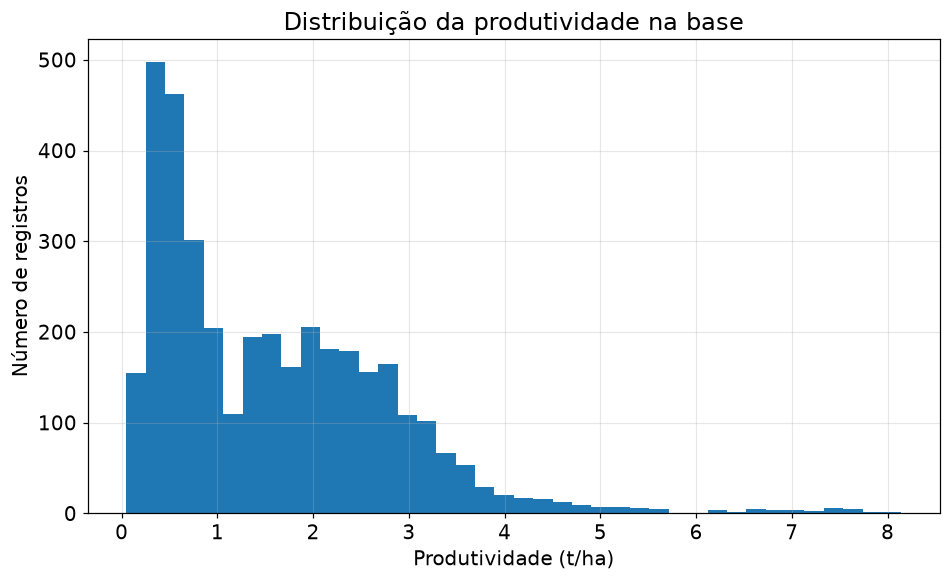

In [9]:
fig, ax = plt.subplots()
ax.hist(dados["produtividade_t_ha"], bins=40)
ax.set_xlabel("Produtividade (t/ha)")
ax.set_ylabel("Número de registros")
ax.set_title("Distribuição da produtividade na base")
plt.show()

## Quanto de cada cultura

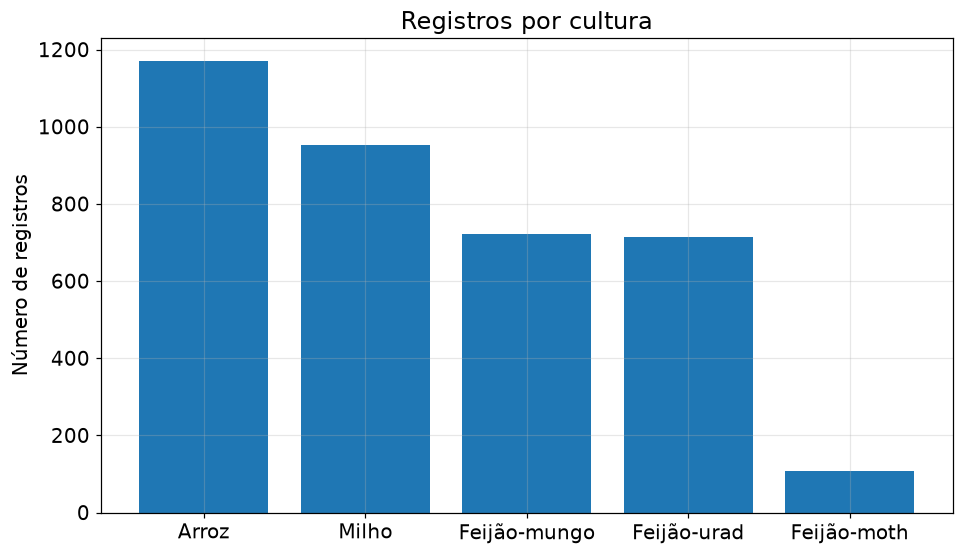

In [10]:
contagem = dados["cultura"].value_counts()

fig, ax = plt.subplots()
ax.bar(contagem.index, contagem.values)
ax.set_ylabel("Número de registros")
ax.set_title("Registros por cultura")
plt.show()

## As duas produtividades conversam?

A base traz a produtividade informada na fonte e a produtividade recalculada como
`producao_t ÷ area_ha`. As duas deveriam dizer a mesma coisa.

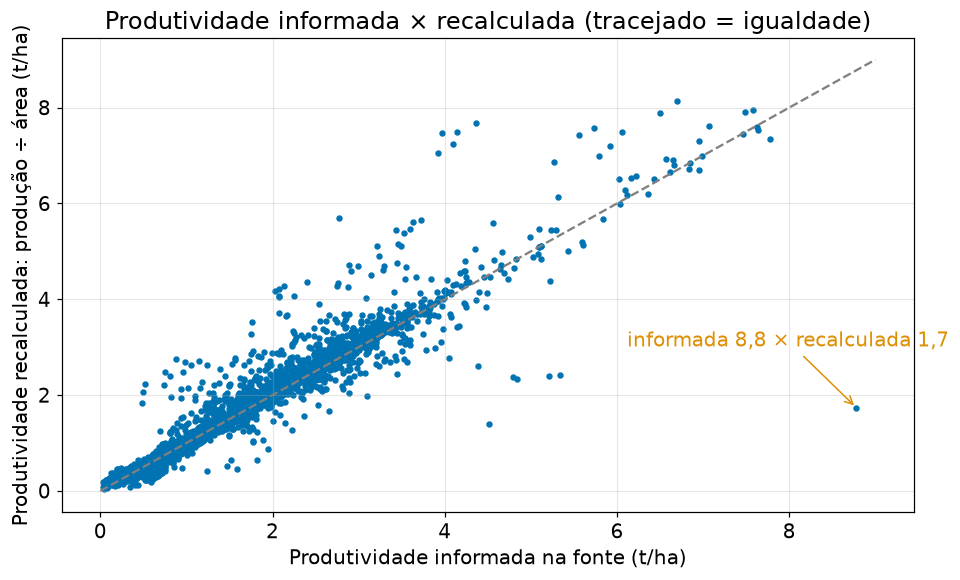

In [11]:
fig, ax = plt.subplots()
ax.scatter(
    dados["produtividade_informada"], dados["produtividade_t_ha"], s=10, color="#0173B2"
)
ax.plot([0, 9], [0, 9], linestyle="--", color="gray")

extremo = dados.loc[
    (dados["produtividade_informada"] - dados["produtividade_t_ha"]).idxmax()
]
ax.annotate(
    f"informada {extremo['produtividade_informada']:.1f} ×"
    f" recalculada {extremo['produtividade_t_ha']:.1f}".replace(".", ","),
    xy=(extremo["produtividade_informada"], extremo["produtividade_t_ha"]),
    xytext=(-150, 40),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->", "color": "#DE8F05"},
    color="#DE8F05",
)

ax.set_xlabel("Produtividade informada na fonte (t/ha)")
ax.set_ylabel("Produtividade recalculada: produção ÷ área (t/ha)")
ax.set_title("Produtividade informada × recalculada (tracejado = igualdade)")
plt.show()

In [12]:
divergencia = (
    dados["produtividade_t_ha"] - dados["produtividade_informada"]
).abs() / dados["produtividade_informada"]

print(f"divergência mediana: {divergencia.median():.1%}")
print(f"registros que divergem mais de 10%: {(divergencia > 0.10).mean():.1%}")

divergência mediana: 5.4%
registros que divergem mais de 10%: 33.1%


## O que levamos daqui

- A base tem uma **variável central** — a produtividade — e variáveis de contexto ao redor dela:
  clima, manejo, área, região, cultura e safra.
- Não há valores ausentes, mas há uma **inconsistência real** entre duas colunas que deveriam
  dizer a mesma coisa. Seguimos com a produtividade recalculada, que fecha com produção e área.
- Produtividade é receita por hectare: cada décimo de tonelada a mais, multiplicado pela área
  plantada, é dinheiro na conta de quem produz. É essa a pergunta de negócio que vai nos guiar.
- A distribuição da produtividade tem uma forma que ainda não sabemos ler. Guarde esse gráfico:
  a próxima aula é teórica e ensina justamente a interpretar formas de distribuição.